# **Practical Assignment 3**
# **Team: Minnie, Fran**
## Introduction
In this assignment, it is expected that you learn and understand how to apply Deep Reinforcement Learning (DeepRL) techniques to control an agent in a simulation environment. This assignment will focus on image-based state representation (Part I) and affordance-based state representation (Part II). This assignment is part of your continuous evaluation. You should provide a report and notebooks (.ipynb), which include your development and analysis for the requested tasks.

[Part 1](#scrollTo=cCcmSW2hI9SV&line=9&uniqifier=1)


[Part 2](#scrollTo=Hce6eLAiJwTL&line=1&uniqifier=1)

# Assignment 3 Part 1
In the first part, your main goal is to implement a Convolutional Neural Network (CNN) that takes as input an RGB image (or a stack of RGB images) corresponding to the visual representation of the OpenAI CarRacingObstacles-v3 environment. Since this is a hard scenario, and considering time constrains in the Google Colab, the goal condition is to obtain a total reward per episode higher than 500 in the previous 20 episodes (in both control modes), however keep in mind that it is possible to obtain a value close to 900 using DQN or Double Dueling DQN, depending on the network and hyperparameters selected. By default, the CarRacingObstacles-v3 generates a new car track per episode, take this into account when analyzing your results. A set of seeds was left exclusively for evaluation (test) for the best policies. You must implement DQN and Double Dueling DQN, and train the models in the environment’s discrete and continuous modes (see the UseContinuousControl flag), to that end, you must complete the following tasks:  
• Prepare a CNN and modify the necessary hyperparameters in the provided Google Colab notebook (check the GitHub repository3);  
• Implement the Double Dueling DQN in the same Google Colab notebook, use the available flags to switch between methods;  
• Train each model in continuous and discrete modes, compare the results between each model and each control modality.  
• Evaluate the best models in 5 random tracks and in 5 random environments (see the UseRandomize flag);  
• Experiment with Q-learning hyperparameters (Deep layers, action replay memory, batch size, gamma, epsilon, episode, etc). The provided Google Colab notebook lets you define the number of consecutive frames used to represent the state and the number of iterations the same action is executed in the environment.  
• Activate the different types of obstacles (e.g., n static obstacles =5, n dynamic obstacles=5, n mountains=5 or use ghost=True) and compare with the previous results, explain the reasons (if any) for the different results obtained (set UseRandomize=False, the idea is to evaluate how small changes in the state influence the policy).   

Note: If for some reason you are unable to achieve the minimum results, you can force the environment to use the same seed and always generate the same track, which will make the environment easier.  

In [ ]:
# from google.colab import drive
# drive.mount("/content/drive")

# !mkdir -p /content/drive/MyDrive/APA2025_patches
# !cp -f /content/CarRacingWObstacles/car_racing_obstacles.py \
#       /content/drive/MyDrive/APA2025_patches/car_racing_obstacles.py

# print(" Guardado en Drive:",
#       "/content/drive/MyDrive/APA2025_patches/car_racing_obstacles.py")


Set up Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

save_dir = "/content/drive/MyDrive/modelos_entrenados/APA2025_CarRacing"
os.makedirs(save_dir, exist_ok=True)

print("Saving here:", save_dir)

Mounted at /content/drive
Saving here: /content/drive/MyDrive/modelos_entrenados/APA2025_CarRacing


In [ ]:
REPO_URL = "https://github.com/luisgarrote/CarRacingWObstacles.git"
REPO_DIR = "/content/CarRacingWObstacles"

PATCH_FILE = "/content/drive/MyDrive/APA2025_patches/car_racing_obstacles.py"
TARGET_FILE = f"{REPO_DIR}/car_racing_obstacles.py"

print("PATCH_FILE:", PATCH_FILE)
print("TARGET_FILE:", TARGET_FILE)

PATCH_FILE: /content/drive/MyDrive/APA2025_patches/car_racing_obstacles.py
TARGET_FILE: /content/CarRacingWObstacles/car_racing_obstacles.py


Clone repository + apply your patched file + install (second)

In [ ]:
import os

# 1) Clonar limpio siempre (así cada 'Ejecutar todas' es reproducible)
!rm -rf {REPO_DIR}
!git clone {REPO_URL} {REPO_DIR}

# 2) Verificar que existe el patch en Drive
if not os.path.exists(PATCH_FILE):
    raise FileNotFoundError(
        "ERROR: I can't find your patched car_racing_obstacles.py in Drive..\n"
        "Save it once in Drive at: " + PATCH_FILE
    )

# 3) Sobrescribir el archivo del repo con tu versión parcheada (UNA línea clave)
!cp -f {PATCH_FILE} {TARGET_FILE}

print("OK: Patch applied. Target file:")
!ls -l {TARGET_FILE}

# 4) Instalar dependencias del repo (si ya están, no pasa nada)
%cd {REPO_DIR}
!pip -q install swig
!pip -q install -r requirements.txt

# 5) Instalar el repo en modo editable (importará desde este código fuente)
!pip -q install -e .
%cd /content

print("OK: Repo installed (editable) and ready to go")

Cloning into '/content/CarRacingWObstacles'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 59 (delta 19), reused 19 (delta 19), pack-reused 38 (from 1)
Receiving objects: 100% (59/59), 127.58 KiB | 9.11 MiB/s, done.
Resolving deltas: 100% (27/27), done.
OK: Patch applied. Target file:
-rw-r--r-- 1 root root 32495 Dec 27 20:12 /content/CarRacingWObstacles/car_racing_obstacles.py
/content/CarRacingWObstacles
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 59.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
/content
OK: Repo installed (editable) and ready to go


Imports + verify that it uses YOUR file + register environment (third)

In [ ]:
import sys, os, importlib
import numpy as np
import torch
import gymnasium as gym

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)

REPO_DIR = "/content/CarRacingWObstacles"
TARGET_FILE = f"{REPO_DIR}/car_racing_obstacles.py"

# 1) Verificar que el archivo está donde esperamos
if not os.path.exists(TARGET_FILE):
    raise FileNotFoundError(f"ERROR: Does not exist: {TARGET_FILE}")

# 2) AÑADIR EL REPO AL PATH (esto arregla el ModuleNotFoundError)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

# 3) Import + verificación de ruta
import car_racing_obstacles
importlib.reload(car_racing_obstacles)
print("OK: car_racing_obstacles loaded from:\n", car_racing_obstacles.__file__)

from car_racing_obstacles import CarRacingObstacles

# 4) Registrar entorno (si ya existe, lo avisará)
try:
    gym.register(
        id="CarRacingObstacles-v3",
        entry_point="car_racing_obstacles:CarRacingObstacles",
    )
except Exception as e:
    print("Notice (existing registration, this is normal):", e)


Device: cuda:0
OK: car_racing_obstacles loaded from:
 /content/CarRacingWObstacles/car_racing_obstacles.py


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from matplotlib.pyplot import figure

import gymnasium as gym
import torch
from torch.utils import data
import torch.nn as nn
import torch.optim as optim
import torch.autograd as autograd
import random
from gymnasium import wrappers
import copy
from gymnasium.wrappers import RecordVideo

import glob
import io
import base64
from IPython.display import HTML
from IPython import display as ipythondisplay

Smoke test to check that everything is working correctly

A smoke test is a minimal test to verify that:

- the package was installed,

- the environment is registered as CarRacingObstacles-v3,

- you can perform reset() and step() without errors.

In [ ]:
import gymnasium as gym
from car_racing_obstacles import CarRacingObstacles
# if CarRacingObstacles-v3 not found
gym.register(
    id="CarRacingObstacles-v3",
    entry_point="car_racing_obstacles:CarRacingObstacles",
)

env = gym.make("CarRacingObstacles-v3", render_mode="human") #rgb_array
obs, info = env.reset()

done = False
while not done:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated

env.close()

/usr/local/lib/python3.12/dist-packages/gymnasium/envs/registration.py:636: UserWarning: WARN: Overriding environment CarRacingObstacles-v3 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")


In [ ]:
!ls -l /content/CarRacingWObstacles

total 256
-rw-r--r-- 1 root root 147148 Dec 27 20:12 APA2025_DeepRL_PartI.ipynb
-rw-r--r-- 1 root root  15317 Dec 27 20:12 car_dynamics.py
drwxr-xr-x 2 root root   4096 Dec 27 20:13 car_racing_obstacles.egg-info
-rw-r--r-- 1 root root  32495 Dec 27 20:12 car_racing_obstacles.py
-rw-r--r-- 1 root root  29583 Dec 27 20:12 car_racing.py
-rw-r--r-- 1 root root   1744 Dec 27 20:12 demo.py
-rw-r--r-- 1 root root     53 Dec 27 20:12 __init__.py
drwxr-xr-x 2 root root   4096 Dec 27 20:13 __pycache__
-rw-r--r-- 1 root root   1894 Dec 27 20:12 README.md
-rw-r--r-- 1 root root    186 Dec 27 20:12 register_envs.py
-rw-r--r-- 1 root root     34 Dec 27 20:12 requirements.txt
-rw-r--r-- 1 root root    353 Dec 27 20:12 setup.py


Deep RL Replay Buffer

In [ ]:
# En Deep RL (DQN y variantes), no entrenas con las transiciones “en orden” según llegan porque:

# Los datos consecutivos están muy correlacionados (frames seguidos se parecen).

# Si entrenas así, el aprendizaje es inestable y puede divergir.

# Necesitas “mezclar” experiencias para aproximar el supuesto de i.i.d. del SGD.

# --> El ReplayBuffer guarda transiciones (s, a, r, s', done) y luego, durante el entrenamiento, extrae mini-batches aleatorios para actualizar la red.

In [ ]:
import numpy as np

class ReplayBuffer:
    def __init__(self, size):
        self.size = size            # tamaño del buffer
        self.counter = 0            # total de transiciones insertadas (crece siempre)

        self.state_buffer = []      # s
        self.action_buffer = []     # a
        self.reward_buffer = []     # r
        self.new_state_buffer = []  # s'
        self.terminal_buffer = []   # done

    def __len__(self):
        # cuántas transiciones "usables" hay ahora mismo
        return min(self.counter, self.size)

    def store_tuples(self, state, action, reward, new_state, done):
        # Mientras el buffer aún no haya alcanzado size, va creciendo (placeholders)
        if len(self.state_buffer) < self.size:
            self.state_buffer.append(None)
            self.action_buffer.append(None)
            self.reward_buffer.append(None)
            self.new_state_buffer.append(None)
            self.terminal_buffer.append(None)

        # índice circular donde se escribe (pero sin romper el significado de counter)
        idx = self.counter % self.size

        # Guarda cada componente en su lista correspondiente, en el mismo índice.
        self.state_buffer[idx] = state
        self.action_buffer[idx] = action
        self.reward_buffer[idx] = reward
        self.new_state_buffer[idx] = new_state
        self.terminal_buffer[idx] = done

        # counter = total transiciones vistas (NO circular)
        self.counter += 1

    def sample_buffer(self, batch_size):
        # cantidad real de experiencias disponibles para muestrear
        max_buffer = len(self)

        # Seguridad: si no hay suficientes, que lo avise claramente
        if max_buffer < batch_size:
            raise ValueError(f"Not enough samples: {max_buffer} < {batch_size}")

        # Selecciona batch_size índices aleatorios sin reemplazo
        batch = np.random.choice(max_buffer, batch_size, replace=False)

        state_batch = []
        action_batch = []
        reward_batch = []
        new_state_batch = []
        done_batch = []

        for a in batch:
            state_batch.append(self.state_buffer[a])
            action_batch.append(self.action_buffer[a])
            reward_batch.append(self.reward_buffer[a])
            new_state_batch.append(self.new_state_buffer[a])
            done_batch.append(self.terminal_buffer[a])

        return state_batch, action_batch, reward_batch, new_state_batch, done_batch

In [ ]:
# A) Control de “warm-up”

# Si el training loop llama sample_buffer cuando aún no hay suficientes transiciones, te va a fallar.

# Solución típica (en el training loop): no entrenar hasta tener min_replay_size (ej. 5k o 10k transiciones).

# --> Esto no se implementa aquí, suele implementarse en el loop:
# “if counter < batch_size: return / skip training”.

In [ ]:
from torchvision import datasets, models
class DQN(nn.Module):

    def __init__(self, inputs, outputs):
        super(DQN, self).__init__()

        self.input_size=inputs;     # número de canales de entrada de la imagen: 3 si usas RGB, 12 si apilas 4 frames RGB (3×4)
        self.output_size=outputs;   # número de acciones discretas (tamaño de action_space)


        # --- CNN features (Nature-DQN style) ---
        self.features = nn.Sequential(
            nn.Conv2d(inputs, 32, kernel_size=8, stride=4),  # -> (B, 32, 23, 23)
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2),      # -> (B, 64, 10, 10)
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, stride=1),      # -> (B, 64, 8, 8)
            nn.ReLU(inplace=True),
        )

        # --- compute flatten size dynamically (avoid hardcoding like 588) --->    (Con esta arquitectura, el tamaño correcto sería 4096, pero lo mejor es lo de arriba: calcular n_flat con un dummy input y así no se rompe si vuelves a tocar convs, apilas frames, etc.)
        with torch.no_grad():         # No guarda gradientes porque esto no es entrenamiento, es solo cálculo de forma
            dummy = torch.zeros(1, inputs, 96, 96)  # Crea un “batch” de 1 imagen falsa (todo ceros), Supone que el input real es 96×96
            n_flat = self.features(dummy).view(1, -1).size(1)  # should be 4096 --> Pasa el dummy por la CNN → produce tensor (1, 64, 8, 8), view(): Aplana a (1, 4096), size(1): Toma el tamaño de la dimensión features → 4096
        # RESUMEN: Crea una imagen ficticia (dummy) y la pasa por la CNN para saber cuántos valores salen al aplanar. Esto evita errores al cambiar la arquitectura


        self.n_flat = n_flat  # keep for reference/debug --> Guarda ese número por si quieres imprimirlo o usarlo en debugging

        # --- DQN head ---    (Convierte el vector de features (4096) en Q-values (uno por acción))
        self.layers = nn.Sequential(
            nn.Linear(n_flat, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, outputs)
        )

        # Bloque Dueling (shared + heads)
        # --- Dueling shared layer ---
        self.layersdueling = nn.Sequential(                  # crea representación compartida z de tamaño 512
            nn.Linear(n_flat, 512),
            nn.ReLU(inplace=True)
        )

        # --- Dueling heads ---
        self.advantage = nn.Sequential(                     # qué tan buena es cada acción sobre ese estado A(s, a) --> de z a un vector con una ventaja por acción (B, outputs)
            nn.Linear(512, outputs)
        )

        self.value = nn.Sequential(                   # qué tan bueno es el estado en general V(s) --> de z a un escalar (B, 1)
        nn.Linear(512, 1)
        )

        # flag to switch behavior (set externally: net.use_dueling = True/False) --> Flag para cambiar entre DQN y Dueling
        self.use_dueling = False


###### DQN/Double DQN configuration

###########    ############    #################
#         #    #          #    #               #
#   IMG   # -> # features # -> #     layers    #    .... argmax ....
#         #    #  (CONVs) #    #     (FCs)     #
###########    ############    #################


###### Dueling configuration
                                                    #############
###########    ############    #################    # advantage #
#         #    #          #    #               # -> #############   ... value + advantage  - advantage.mean() ... argmax ...
#   IMG   # -> # features # -> # layersdueling # -> #############
#         #    #  (CONVs) #    #     (FCs)     #    #   value   #
###########    ############    #################    #############


    def forward(self, x):             # Qué hace (general): define cómo la red transforma una entrada x (imagen) en salida Q-values (o en dueling: combina value+advantage para Q)
      # x expected shape: (B, C, H, W)
      # Normalize if coming as uint8 [0..255]  --->   Asegura que x esté en float y normalizado a [0,1] si venía como imagen 0–255
      x = x.float()
      if x.max() > 1.0:
          x = x / 255.0     # normaliza [0, 1] si viene como [0..255], aunque creo que ReplayBuffer ya lo da en uint8 (con esto nos aseguramos)

      # Extrae features con CNN y aplana
      x = self.features(x)                    # Aplica convs y relus --> Forma típica: (B, 64, 8, 8)
      x = x.view(x.size(0), -1)                 # flatten --> Aplana a (B, n_flat)

      if getattr(self, "use_dueling", False):                 # Devuelve Q-values según modo
          z = self.layersdueling(x)          # (B, 512)
          adv = self.advantage(z)            # (B, outputs)
          val = self.value(z)                # (B, 1)
          q = val + adv - adv.mean(dim=1, keepdim=True)  # (B, outputs)       --> fórmula dueling
          return q
      else:
          return self.layers(x)              # (B, outputs)   --> sino hay dueling entonces usa self.layers directamente


    def policy(self,state):             # Qué hace (general): devuelve la mejor acción (greedy) sin exploración
       with torch.no_grad():        # No calcula gradientes: más rápido y evita “ensuciar” el grafo
            return self.__call__(state.unsqueeze(0)).argmax()       # state.unsqueeze(0): Añade dimensión batch: de [C,H,W] pasa a [1,C,H,W], self.__call__(...): Llama internamente a forward (PyTorch) y .argmax(): Devuelve el índice de la acción con mayor Q


    def getPolicy(self,state,eps_threshold):        # Qué hace (general): política epsilon-greedy: con probabilidad 1−ϵ: acción greedy, con probabilidad ϵ: acción aleatoria
        sample = random.random()      # uniforme en [0,1)
        if sample > eps_threshold:      # Exploit (greedy) si superas epsilon
            with torch.no_grad():
                return self.__call__(state.unsqueeze(0)).argmax()
        else:               # Explore eligiendo acción aleatoria
            return  torch.tensor(random.randrange(self.output_size), device=device, dtype=torch.long)


  # Nota: modificar parámetro "eps_threshold" para que al principio explore mucho y con el tiempo vaya decayendo y explote las mejores acciones más


DQN movie generation (for visual evaluation in Google Colab)

In [ ]:
# Este bloque define una función createMovie(...) que:

  # Crea el entorno CarRacingObstacles-v3 con render_mode="rgb_array" para capturar frames.

  # Envuelve el entorno con RecordVideo para grabar un .mp4.

  # Ejecuta un episodio con una política (tu Network) usando:

  # Frame stacking (apila varios frames para dar “memoria” a la red).

  # ControlSteps (repite la misma acción varios pasos; típico “frame skip”).

  # Acciones discretizadas (aunque el entorno sea continuo, el DQN elige un índice y se traduce con action_space[action.item()]).

  # Cierra el entorno, busca el .mp4 grabado y lo muestra embebido en Colab.

# --> Es una celda de evaluación visual: no entrena, solo te ayuda a ver “si conduce bien o mal”

In [ ]:

def createMovie(Network,Filename,UseRandomizer,UseContinuous):      # crea un vídeo del comportamiento de Network --> Filename: nombre de carpeta donde se guardará el vídeo, UseRandomizer: activa/desactiva randomización del dominio/entorno, UseContinuous: configura el entorno en modo continuo (pero ojo: aquí sigues usando acciones discretizadas)

    env1 = gym.make("CarRacingObstacles-v3", render_mode="rgb_array",domain_randomize=UseRandomizer, continuous=UseContinuous)    # crea el entorno
    envX = env1
    envX = RecordVideo(env1, video_folder='./videos/'+Filename,  episode_trigger = lambda x: True)        # wrapper que graba vídeos de episodios

    new_state = envX.reset(options={"randomize": UseRandomizer})      # Resetea el entorno y obtiene la primera observación -->  options={"randomize": UseRandomizer}: opción adicional para randomizar (además de domain_randomize=).


    stackedStateX=[np.rollaxis(new_state[0], 2, 0).copy() for i in range(FrameStack)];   # Crea una lista con FrameStack copias del primer frame (para iniciar el stack) --> np.rollaxis(..., 2, 0): Convierte la imagen de formato HWC (96,96,3) a CHW (3,96,96), que es lo esperado por Conv2d
    state =torch.from_numpy(np.reshape(np.array(stackedStateX),(FrameSize*FrameStack,96,96)) ).float().to(device)   # Esto conecta con la Tarea I: el estado puede ser “un frame” o “stack de frames” --> FrameSize aquí normalmente es 3 (RGB channels), FrameStack: cuántos frames apilas para representar el estado

    i=0       # contador de pasos
    Network.eval()     # modo evaluación
    resetStatus=0;      # variable que aquí no se usa (posible resto de versiones anteriores)


    while True:
        envX.render()         # render() en rgb_array suele no ser necesario para grabar (ya que el wrapper captura), pero no hace daño

        action = Network.policy(state);       # Acción greedy: elige la mejor acción según Q-values, Devuelve un índice 0..n_actions-1 como tensor
        reward=0
        for x in range(ControlSteps):           # ControlSteps: repite la misma acción varios pasos (frame skip) --> reduce FPS efectivo y estabiliza control
            new_state, r, done, truncated, _  = envX.step(action_space[action.item()])      # action.item(): convierte tensor a int, envX.step(action): ejecuta acción y devuelve (obs, reward, done, truncated, info)
            reward+=r
            if(done or truncated):
                break
        stackedStateX.pop(0)          # Quita el frame más viejo del stack (FIFO)

        # Con la descripción del profe: el reward incluye penalización por frame (-0.1). Si repites acción 4 steps, acumulas 4 veces esa penalización, etc, tmb acumulas recompensas

        stackedStateX.append(np.rollaxis(new_state, 2, 0).copy())       # Añade el frame nuevo al stack --> ALERTA! Dependiendo de la versión, puede ser inconsistente. Si te da error, esta es una causa típica
        state=torch.from_numpy(np.reshape(np.array(stackedStateX),(FrameSize*FrameStack,96,96))).float().to(device)     # Reconstruye el tensor estado apilado con el nuevo stack
        i=i+1;
        if done or truncated:           # incrementas el contador, Si terminó el episodio → sales del while
          break;

    # Cierra wrappers y entorno
    envX.close()
    env1.close();

    # Vuelve a modo train() (para no afectar el resto del notebook si sigues entrenando después)
    Network.train()

    # Busca mp4 en la carpeta.
    # Lee bytes del mp4.
    # Codifica a base64.
    # Inserta HTML <video> para mostrarlo en Colab.
    # Si no hay mp4, avisa
    mp4list = glob.glob('./videos/'+Filename+'/*.mp4')
    if len(mp4list) > 0:
        mp4 = mp4list[0]
        video = io.open(mp4, 'r+b').read()
        encoded = base64.b64encode(video)
        ipythondisplay.display(HTML(data='''<video alt="test" autoplay
                loop controls style="height: 400px;">
                <source src="data:video/mp4;base64,{0}" type="video/mp4" />
             </video>'''.format(encoded.decode('ascii'))))
    else:
        print("Could not find video")

Dummy Net with random policy

In [ ]:
# Este bloque define una red “dummy” llamada RandomNet que no aprende nada. Su objetivo es servir como baseline:

  # En vez de elegir acciones según Q-values, elige una acción aleatoria.

# Se usa para:

  # Comparar visualmente (vídeo) con tu agente entrenado.

  # Confirmar que el pipeline de createMovie() funciona (si graba un episodio con una policy random, el sistema está bien conectado).

  # Tener una referencia: “esto es lo que pasa cuando NO hay aprendizaje”.

# En resumen: es un agente aleatorio para comparación

In [ ]:
class RandomNet(nn.Module):

    def __init__(self,outputs):
        super(RandomNet, self).__init__()       # guarda el número de acciones posibles
        self.output_size=outputs;


    def forward(self, x):     # no hace inferencia real (devuelve lo que le pasas), No calcula Q-values --> En realidad, forward aquí es irrelevante porque el agente toma decisiones usando policy(), no usando forward()
        return  x

    def policy(self,state):         # devuelve un índice de acción al azar en [0, output_size-1]
       return  torch.tensor([[random.randrange(self.output_size)]], device=device, dtype=torch.long)

# Este bloque es código base para baseline y debug.


In [ ]:
# 6) Cómo se usa típicamente en el notebook

# Normalmente se hace:

# randomnet = RandomNet(n_actions)
# createMovie(randomnet, "random", UseRandomize, UseContinuousControl)


# y verás que el coche:

  # zigzaguea,

  # se sale de la pista,

  # termina rápido,

  # reward malo.

# Eso te sirve para confirmar que tu agente entrenado realmente mejora sobre el azar.

Parameters

In [ ]:



###################################################
###################################################
###################################################
UseRandomize=False;         # Según el profe: con True se randomizan tracks y colores; con False “solo tracks random” --> Para entrenar al principio suele ser más fácil empezar con False (menos variabilidad) y luego generalizar con True
UseContinuousControl=True;      # El entorno se crea en modo continuo, Pero como tu método es DQN (discreto), luego discretizas un conjunto de acciones continuas
###################################################
###################################################
###################################################


if UseContinuousControl:
    steer_vals = [-1.0, -0.5, 0.0, 0.5, 1.0]
    gas_vals   = [0.0, 0.3, 0.6, 1.0]
    brake_vals = [0.2, 0.5]  # frenadas reales (sin 0 aquí)

    action_space = []

    # gas (sin freno)
    for s in steer_vals:
        for g in gas_vals:
            action_space.append(np.array([s, g, 0.0], dtype=np.float32))

    # freno (solo con gas=0) --> o aceleras o frenas
    for s in steer_vals:
        for b in brake_vals:
            action_space.append(np.array([s, 0.0, b], dtype=np.float32))
      # Ejemplos:
        # [0.0, 0.0, 0.5] → frenar recto
        # [-0.5, 0.0, 0.2] → frenar mientras giras suave izq (para tomar curva cerrada o corregir derrape

    # acciones extra útiles (recovery)
    action_space += [
        np.array([0.0, 0.0, 0.8], dtype=np.float32),  # freno fuerte recto --> OPCIÓN DE EMERGENCIA
    ]

# ¿Por qué “sin freno”?
# Porque en conducción real (y en este entorno) gas y freno a la vez suele ser mala idea para aprender: genera comportamientos inconsistentes y ruido.

else:
    action_space = [0,1,2,3,4]    #  nothing','left','right','gas','brake'

n_actions=len(action_space)     # Número de acciones posibles. Esto se usa para: tamaño de salida de la red (outputs), muestreo random, argmax etc.

#hyper-parameters
TotalEpisodes=600
;
MaxSteps=1000;      # máximo steps por episodio
ControlSteps=2; # number of iterations the same action is executed in the environment --> Pros: reduce ruido, acelera “avance” en el entorno     Contras: control menos fino, puede empeorar curvas si es muy alto
FrameStack=4 # number of consecutive frames used to represent the state --> 4 suele ayudar mucho en conducción para estimar velocidad y dinámica (porque de un frame no “ves” movimiento)
FreezeCounter=10; # (10) clone the model every X episodes  --> Cada X episodios copias pesos de policy_net a target_net (Si actualizas demasiado a menudo, puede ser inestable; demasiado lento, aprende más lento)
BatchSize=64;   # 32
exploration_threshold=1     # Empiezas con epsilon=1 (100% random)
exploration_threshold_min=0.07    # Baja hasta 0.07 [0.05–0.10]  porque hemos extendido action_space en Continous
exploration_decay=0.996   # Decae multiplicativamente cada episodio (o cada step, depende del loop) --> Si decae demasiado rápido, el agente deja de explorar antes de aprender bien [0.96-0.98] porque hemos extendido action_space en Continuos
discount_factor=0.99    # Importancia del futuro --> En conducción, valores entre 0.95 y 0.99 suelen funcionar
LearningRate=1e-4     # LR típico para DQN con CNN: Si ves que no aprende nada: a veces subir a 2.5e-4 ayuda, Si diverge: bajar a 5e-5

SaveAtCounter=50 # save model or video at every X episodes --> Cada 50 episodios guarda vídeo: es mejor hacer menos videos durante el entreno porque esto relentiza --> subir a 100 para que hayan 5 videos si TotalEisodes=500

# Heurística del profe para cortar episodios malos:
ResetCounter=50 # maximum number of experiences with bad performance (max=InitCounter+ResetCounter) --> si acumulas “mal rendimiento” 30 más, cortas.
InitCounter=50 # minimum number of experiences per episode --> al menos deja correr 30 experiencias
# Nota: No es estándar de DQN puro; es una “ayuda” para que Colab no se quede entrenando en episodios totalmente perdidos

FrameSize=3; # 3 if RGB 1 if grayscale --> Canales por frame: Para este env es RGB → 3.

BufferSize=50000  # max number of experiences in the buffer (may need to be smaller if CUDA memory errors occur) --> Capacidad del replay buffer: En entornos visuales, 50k–200k suele ir mejor si puedes


# use these flags to enable Double DQN and Duelinng (Dueling DQN or Double Dueling DQN) --> Esos flags en el bloque de hiperparámetros solo crean variables (son “config”). Por ello, despues de instanciar las redes hacemos policy_net.use_dueling = useDueling, target_net.use_dueling = useDueling PARA QUE SE APLIQUE CORRECTAMENTE EN LA CNN
usedoubleDQN=True
useDueling=True

# Estos flags determinan qué target y qué arquitectura usas:
  # useDueling=True implica que tu red debería usar value+advantage en el forward.
  # usedoubleDQN=True implica que en el cálculo de target se usa la fórmula Double:
      # acción elegida por policy_net
      # valor estimado por target_net


Initialization and Parameters:


In [ ]:
env = gym.make("CarRacingObstacles-v3", render_mode="rgb_array",domain_randomize=UseRandomize, continuous=UseContinuousControl)   # Crea el entorno de CarRacing con obstáculos
spec = gym.spec("CarRacingObstacles-v3")      # Obtiene el “spec” del entorno (metadata/config) --> se queda como información y no se usa


#network DQN
policy_net = DQN(FrameSize*FrameStack, n_actions).to(device)        # Si cambias FrameStack, aquí automáticamente suben canales
target_net = DQN(FrameSize*FrameStack, n_actions).to(device)        # Crea una segunda red con la misma arquitectura, PERO esta no se entrena
target_net.load_state_dict(policy_net.state_dict())             # Copia los pesos de policy_net → target_net --> Así ambas empiezan idénticas.

# Por qué existe target_net:
# En DQN, el target se calcula con una red “semi-congelada” para evitar oscilaciones. Sin esto, el entrenamiento suele ser muy inestable.

# “Ahora se lo comunico a la red para que su forward() lo aplique” --> parámetros ajustados antes en el bloque de Parameters
policy_net.use_dueling = useDueling
target_net.use_dueling = useDueling

target_net.eval()       # Pone target_net en modo evaluación: desactiva dropout (si existiera), fija batchnorm (si existiera) --> Es correcto: target_net se usa solo para inferencia

buffer = ReplayBuffer(BufferSize);    # Crea el buffer con capacidad BufferSize --> Guardará las tuplas (s, a, r, s', done) para muestrear batches aleatorios.

optimizer = torch.optim.Adam(policy_net.parameters(), lr=LearningRate)      # Adam para actualizar solo los parámetros de policy_net
loss=  torch.nn.SmoothL1Loss()      # Define la pérdida Huber (Smooth L1), Se usa mucho en DQN porque es menos sensible a outliers que MSE

In [ ]:
# Este bloque prepara TODO lo necesario para entrenar con DQN:
  # Crea el entorno (env) con los flags que definiste.
  # Instancia dos redes:
      # policy_net: la red que se entrena (se actualiza con gradiente).
      # target_net: red “congelada” que se usa para calcular objetivos (targets) y estabilizar entrenamiento.
  # Inicializa el Replay Buffer, donde se guardan transiciones.
  # Define:
      # Optimizer (Adam)
      # Función de pérdida (Huber / SmoothL1)

DQN training

In [ ]:
def trainModel(buffer_data):
    # Warm-up mínimo (además de tu MIN_REPLAY_SIZE en el loop)
    if len(buffer) < BatchSize:
        return 0.0

    state_batch, action_batch, reward_batch, new_state_batch, done_batch = buffer_data.sample_buffer(BatchSize)

    # --- Estados: vienen como np.uint8 (B, C, 96, 96) -> float32 en GPU y /255 ---
    states = torch.from_numpy(np.stack(state_batch, axis=0)).to(device).float() / 255.0
    next_states = torch.from_numpy(np.stack(new_state_batch, axis=0)).to(device).float() / 255.0

    # --- Acciones, rewards, dones ---
    actions = torch.tensor(action_batch, device=device, dtype=torch.long).unsqueeze(1)      # (B,1)
    rewards = torch.tensor(reward_batch, device=device, dtype=torch.float32).unsqueeze(1)   # (B,1)
    dones   = torch.tensor(done_batch, device=device, dtype=torch.float32).unsqueeze(1)     # (B,1) 0.0/1.0

    # Aplicar dueling (mejor con hasattr)
    if hasattr(policy_net, "use_dueling"):
        policy_net.use_dueling = useDueling
        target_net.use_dueling = useDueling

    # Q(s,a)
    q_pred_all = policy_net(states)                      # (B, n_actions)
    q_pred = q_pred_all.gather(1, actions)               # (B, 1)

    with torch.no_grad():
        if usedoubleDQN:
            next_actions = policy_net(next_states).argmax(dim=1, keepdim=True)   # (B,1)
            q_next = target_net(next_states).gather(1, next_actions)             # (B,1)
        else:
            q_next = target_net(next_states).max(dim=1, keepdim=True)[0]         # (B,1)

        q_target = rewards + discount_factor * q_next * (1.0 - dones)            # (B,1)

    loss_value = loss(q_pred, q_target)

    optimizer.zero_grad()
    loss_value.backward()
    # torch.nn.utils.clip_grad_norm_(policy_net.parameters(), 10.0)  # recomendable
    optimizer.step()

    return float(loss_value.item())

In [ ]:
# Esta función hace un paso de entrenamiento usando experiencias del Replay Buffer:
  # Comprueba si hay suficientes muestras para un batch.
  # Saca un mini‐batch aleatorio de transiciones (s,a,r,s',done)
  # Calcula:
            # Qpred
            # Qtarget (DQN) O Qtarget (Double DQN)
  # Calcula la loss (Huber) y hace backprop + optimizer.step()

DeepRL Loop

In [ ]:
# Este código entrena tu agente durante TotalEpisodes episodios. En cada episodio:
  # Resetea el entorno y construye el estado inicial con frame stacking.
  # Cada cierto número de episodios:
    # Copia pesos de policy_net a target_net (FreezeCounter).
  # Graba un vídeo para ver cómo va.
  # Dentro del episodio:
    # Selecciona acción con epsilon-greedy (getPolicy).
    # Ejecuta la acción ControlSteps veces (frame-skip).
    # Apila el nuevo frame al estado.
    # Guarda transición en replay buffer.
    # Llama a trainModel(buffer) para actualizar la red.
    # Rompe si: done, trunc o “va fatal” según resetStatus.
  # Actualiza epsilon al final del episodio.
  # Guarda el mejor modelo encontrado

In [ ]:
# =========================
# 🔧 CAMBIO ESENCIAL (AÑADIDO) ANTES DEL FOR
# =========================
modelo = "4"
bestAvg20 = -99999      # mejor media de reward en los últimos 20 episodios (criterio de la práctica)
atAvg20   = 0           # episodio donde ocurrió el bestAvg20 (solo para info)
bestAvg20_path = os.path.join(save_dir, "BestCarRacing_bestAvg20_model_" + modelo + ".pth")  # checkpoint "bueno"

# (Tu código original se mantiene)
loss_val, scores, episodes, events, avg_scores, avg_scores20, exploration = [], [], [], [], [], [], []  # Inicializas listas para guardar métricas

bestScore = -99999  # mejor recompensa total vista
at = 0              # episodio donde ocurrió el bestScore (solo para info)

# ¡OJO! MUY IMPORTANTE --> Si pones MIN_REPLAY_SIZE=10000, asegúrate de que BufferSize >= 10000 (si no, nunca entrenas)
MIN_REPLAY_SIZE = 10000     # (5000 modo discreto, 10mil modo continuo)
TRAIN_EVERY = 4

# =========================
# 🔧 CAMBIO AÑADIDO: Early stopping “inteligente”
# =========================
SOLVE_THRESHOLD = 600          # criterio de la práctica (Avg20 > 600)
SOLVE_STREAK_REQUIRED = 5        # nº de episodios seguidos cumpliendo el criterio para parar “con seguridad”
solved_streak = 0               # contador de racha

# =========================
# 🔧 CAMBIO AÑADIDO: Control de vídeos para acelerar el entrenamiento
# Grabar SOLO: random al inicio, al superar Avg20>200, al superar Avg20>500, y al final (BestAvg20)
# =========================
DISABLE_VIDEOS_DURING_TRAINING = True   # pon False si quieres volver al comportamiento original (cada SaveAtCounter)
VIDEO_THRESHOLD_200 = 200.0
VIDEO_THRESHOLD_500 = 500.0

video_random_done = False
video_200_done = False
video_500_done = False

# Video random al inicio (solo 1 vez) -> útil para comparar
if DISABLE_VIDEOS_DURING_TRAINING and (not video_random_done):
    randomnet = RandomNet(n_actions)
    createMovie(randomnet, "CarRacing_RANDOM_START", UseRandomize, UseContinuousControl)
    video_random_done = True


for f in range(TotalEpisodes):
    done  = False
    score = 0.0      # reward acumulado del episodio
    tloss = 0.0      # acumular loss del episodio
    n_updates = 0    # número de updates de entrenamiento (para promediar la loss)

    # Resetea el entorno. Devuelve (obs, info) y te quedas con obs en new_state
    # seed=6 (útil para hacer siempre la misma pista cuando no aprendes)
    new_state, _ = env.reset(options={"randomize": UseRandomize})  # ,seed=6)

    # Construcción del estado inicial con frame stacking
    stackedState = [np.rollaxis(new_state, 2, 0).copy() for i in range(FrameStack)]
    state_np = np.reshape(np.array(stackedState), (FrameSize * FrameStack, 96, 96)).astype(np.uint8)
    state = torch.from_numpy(state_np).to(device).float() / 255.0

    # Actualización de target_net cada FreezeCounter --> Esto estabiliza el aprendizaje (muy importante para DQN).
    if f % FreezeCounter == 0:
        print("########################################" + str(f) + " of " + str(TotalEpisodes))
        target_net.load_state_dict(policy_net.state_dict())

    # Guardar vídeo cada SaveAtCounter --> Grabas vídeo periódico para ver progreso (Esto puede ralentizar entrenamiento en Colab)
    # 🔧 CAMBIO: solo graba periódicamente si NO hemos desactivado vídeos durante training
    if (not DISABLE_VIDEOS_DURING_TRAINING) and (f % SaveAtCounter == 0):
        # torch.save(policy_net.state_dict(), "v2CarRacing_"+str(f)+'_model.ckpt')
        createMovie(policy_net, "CarRacing_" + str(f), UseRandomize, UseContinuousControl)

    # Variables de “early reset”
    resetStatus = 0   # cuenta cuántas veces estás acumulando recompensa negativa tras InitCounter
    i = 0             # contador global de steps (considerando ControlSteps)

    for F in range(MaxSteps):  # cada iteración corresponde a una acción elegida
        # env.render()
        action = policy_net.getPolicy(state, exploration_threshold)  # Elige acción epsilon-greedy.

        # Ejecutar acción ControlSteps veces
        reward = 0
        for _ in range(ControlSteps):
            # Traduce índice a acción real: action_space[action.item()]
            new_state, r, done, trunc, info = env.step(action_space[action.item()])
            reward += r  # -0.1 por frame + tiles, etc. Repetir acciones hace que se acumulen varias recompensas por cada decisión
            i += 1
            if (done or trunc):  # Si termina el episodio, rompe.
                break

        # Heurística de “episodio malo”
        if reward < 0 and i > InitCounter:
            resetStatus = resetStatus + 1  # si el reward de la última acción es negativo, incrementa resetStatus
        else:
            resetStatus = 0  # si se recupera, lo resetea a 0

        # Actualizar el frame stack con el nuevo frame
        stackedState.pop(0)  # Quitas el frame más antiguo
        stackedState.append(np.rollaxis(new_state, 2, 0).copy())  # Metes el último frame
        next_state_np = np.reshape(np.array(stackedState), (FrameSize * FrameStack, 96, 96)).astype(np.uint8)
        new_state = torch.from_numpy(next_state_np).to(device).float() / 255.0  # Reconstruyes el tensor new_state (estado siguiente apilado)

        score += reward  # Sumar reward total para ese episodio

        # Guardar en replay buffer
        if (F < (MaxSteps - 1)):
          buffer.store_tuples(
          state_np,                 # np.uint8 (CPU)
          int(action.item()),       # int
          float(reward),            # float
          next_state_np,            # np.uint8 (CPU)
          bool(done or trunc))      # # bool

            # buffer.store_tuples(state, action, torch.tensor(reward), new_state, torch.tensor(int(done or trunc)))

            # Guarda transición:
            # state: estado actual (tensor)
            # action: acción (tensor)
            # reward: tensor escalar
            # new_state: estado siguiente
            # done: 0/1

        # Avanzar y entrenar
        state = new_state  # Actualizas el estado.
        state_np = next_state_np   #  IMPRESCINDIBLE: actualiza el estado CPU que se guarda en el replay

        # if buffer.counter > MIN_REPLAY_SIZE and (i % TRAIN_EVERY == 0):
        if len(buffer) > MIN_REPLAY_SIZE and (i % TRAIN_EVERY == 0):
          l = trainModel(buffer)
          if l != 0.0:
              tloss += l
              n_updates += 1


        # Condición de parada del episodio
        if (done or trunc or resetStatus >= ResetCounter):  # Para si termina o si el episodio es “malo” demasiado tiempo
            break

    # Epsilon decay al final del episodio
    exploration_threshold = (exploration_threshold * exploration_decay
                             if exploration_threshold > exploration_threshold_min
                             else exploration_threshold_min)

    # Guardar el mejor modelo --> Si superas el mejor score: guardas pesos a disco
    # (Se mantiene tal cual: BestEpisode por si te interesa tener también el pico)
    if (score > bestScore):
        print("Best EP: ", score, " It: ", F * ControlSteps)
        # Esto guarda un checkpoint con los pesos de policy_net tal como están al final de ese episodio
        bestScore = score
        best_path = os.path.join(save_dir, "BestCarRacing_best_model.pth")
        torch.save(policy_net.state_dict(), best_path)
        at = f

    # Logging de métricas
    exploration.append(exploration_threshold)
    scores.append(score)
    episodes.append(f)
    events.append(F)
    avg_scores.append(score / max(1, F))

    # =========================
    # 🔧 CAMBIO ESENCIAL (AÑADIDO) AQUÍ:
    # en vez de usar "mejor episodio", calculamos y usamos la media de los últimos 20 (BestAvg20)
    # =========================
    avg20_current = np.mean(scores[-20:])           # media de los últimos 20 scores
    avg_scores20.append(avg20_current)              # guardas la media en la lista

    # Guardar el mejor modelo según BestAvg20 --> checkpoint estable (criterio de la práctica)
    if len(scores) >= 20 and (avg20_current > bestAvg20):
        print("Best Avg20: ", avg20_current, " EP: ", f)
        bestAvg20 = avg20_current
        torch.save(policy_net.state_dict(), bestAvg20_path)
        atAvg20 = f

    # Guardar loss promedio del episodio (para report/debug)
    loss_val.append(tloss / max(1, n_updates))

    # Imprimir por pantalla durante el entreno se ha conseguido cumplir la meta de entrenamiento --> esto quiere decir que todo funciona correctamente pero lo que realmente se guarda es el modelo con mejor estrategia (mejor recompensa por episodio) para poder explotarla en un futuro
    # (Aquí cambiamos solo lo esencial: ahora imprimimos usando avg20_current, que ya calculamos arriba)
    if len(scores) >= 20 and avg20_current > 500:
        print("Solved criterion reached:", avg20_current)

    # =========================
    # 🔧 CAMBIO AÑADIDO: Vídeos “por hitos” (solo si DISABLE_VIDEOS_DURING_TRAINING=True)
    # =========================
    if DISABLE_VIDEOS_DURING_TRAINING and len(scores) >= 20:
        if (not video_200_done) and (avg20_current >= VIDEO_THRESHOLD_200):
            createMovie(policy_net, "CarRacing_AVG20_GE_200_EP_" + str(f), UseRandomize, UseContinuousControl)
            video_200_done = True

        if (not video_500_done) and (avg20_current >= VIDEO_THRESHOLD_500):
            createMovie(policy_net, "CarRacing_AVG20_GE_500_EP_" + str(f), UseRandomize, UseContinuousControl)
            video_500_done = True

    # =========================
    # 🔧 CAMBIO AÑADIDO: Early stopping “inteligente” (robusto)
    # =========================
    if len(scores) >= 20 and avg20_current > SOLVE_THRESHOLD:
        solved_streak += 1
    else:
        solved_streak = 0

    if solved_streak >= SOLVE_STREAK_REQUIRED:
        print("Early stop: criterion stable for", SOLVE_STREAK_REQUIRED, "episodes. Avg20:", avg20_current)
        break


# =========================
# 🔧 CAMBIO ESENCIAL (AÑADIDO) AL FINAL:
# cargar el modelo "BestAvg20" en vez del "BestEpisode"
# =========================
state_dict = torch.load(bestAvg20_path, map_location=device)
policy_net.load_state_dict(state_dict)

print("Loaded best Avg20 model from:", bestAvg20_path, "at episode:", atAvg20)

# =========================
# 🔧 CAMBIO AÑADIDO: vídeo final del BestAvg20 (solo 1 vez)
# =========================
createMovie(policy_net, "CarRacing_BEST_AVG20_FINAL_EP_" + str(atAvg20), UseRandomize, UseContinuousControl)


/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


########################################0 of 600
Best EP:  35.9576271186439  It:  342
Best EP:  41.0682539682537  It:  310
Best EP:  47.69999999999983  It:  422
Best EP:  74.60636042402811  It:  698
########################################10 of 600
Best EP:  151.64662576687218  It:  998
Best Avg20:  45.508125716809225  EP:  19
########################################20 of 600
Best Avg20:  46.32981800428787  EP:  20
Best Avg20:  49.50718428535875  EP:  24
Best Avg20:  49.56400968218414  EP:  25
########################################30 of 600
########################################40 of 600
########################################50 of 600
########################################60 of 600
########################################70 of 600
########################################80 of 600
Best Avg20:  51.1845780885722  EP:  83
Best Avg20:  52.562286671535915  EP:  87
Best Avg20:  53.210978016687115  EP:  88
########################################90 of 600
Best EP:  202.47053291536207  

Best Avg20:  235.41309152257662  EP:  236
Best Avg20:  248.33700099676042  EP:  237
Best Avg20:  262.3925214428568  EP:  238
Best Avg20:  279.0685940779915  EP:  239
########################################240 of 600
Best Avg20:  289.0601542845692  EP:  240
Best Avg20:  313.49658285599725  EP:  241
Best Avg20:  316.84076876893863  EP:  242
Best Avg20:  336.41937277079944  EP:  243
Best Avg20:  349.02109532175234  EP:  245
Best Avg20:  372.8551749975129  EP:  246
########################################250 of 600
Best Avg20:  385.2099615522375  EP:  253
Best Avg20:  397.2826309074913  EP:  256
Best EP:  658.3059936908413  It:  998
Best Avg20:  409.53051958879746  EP:  257
Best EP:  702.4022304832631  It:  998
Best Avg20:  420.7503151278308  EP:  258
Best Avg20:  426.9494779143636  EP:  259
########################################260 of 600
Best Avg20:  432.07872141920313  EP:  260
Best EP:  760.3249999999937  It:  998
Best Avg20:  434.02193344167773  EP:  266
Best Avg20:  453.0227542687

Best Avg20:  515.6082798740056  EP:  273
Solved criterion reached: 515.6082798740056
Best Avg20:  528.2678141602837  EP:  274
Solved criterion reached: 528.2678141602837
Solved criterion reached: 527.8286732167776
Best Avg20:  535.3758574817878  EP:  276
Solved criterion reached: 535.3758574817878
Best Avg20:  536.2046318713194  EP:  277
Solved criterion reached: 536.2046318713194
Best EP:  765.7312499999917  It:  998
Best Avg20:  539.3710828471558  EP:  278
Solved criterion reached: 539.3710828471558
Best Avg20:  545.4314355222954  EP:  279
Solved criterion reached: 545.4314355222954
########################################280 of 600
Solved criterion reached: 532.1523001521325
Solved criterion reached: 527.8459311045139
Best Avg20:  550.3357723743545  EP:  282
Solved criterion reached: 550.3357723743545
Best Avg20:  556.9388790506775  EP:  283
Solved criterion reached: 556.9388790506775
Best EP:  861.6999999999921  It:  998
Best Avg20:  594.5787570994574  EP:  284
Solved criterion rea

Plot performance

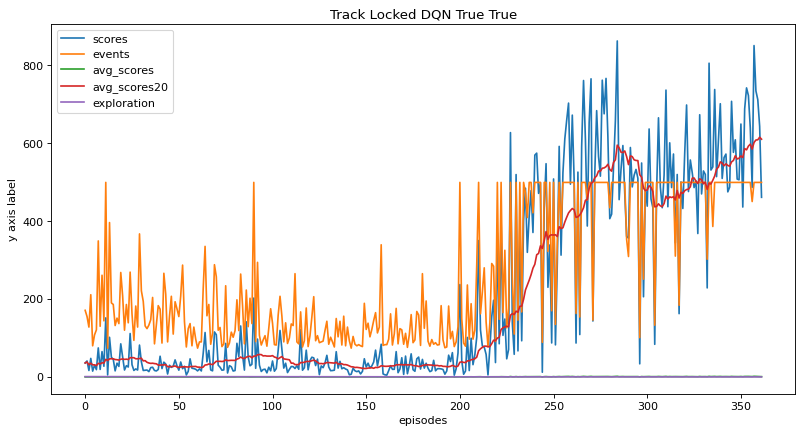

In [ ]:
figure(figsize=(12, 6), dpi=80)
plt.plot(episodes, scores)      # Dibuja reward total por episodio --> ¡OJO! en Tarea I se pide reportar rewards por episodio
plt.plot(episodes, events)        # events contiene F (número de pasos macro ejecutados antes de terminar) --> Te da idea de cuánto “sobrevive” el agente: si aprende, normalmente los episodios duran más (aunque no siempre, porque puede terminar rápido por completar)
plt.plot(episodes, avg_scores)        # Interpretación: reward por paso macro
plt.plot(episodes, avg_scores20)          # Media de los últimos 20 scores --> Esta curva es ideal para comprobar el criterio de éxito “últimos 20 episodios”
plt.plot(episodes, exploration)           # Dibuja epsilon (exploration threshold) --> Debe empezar alto (~1) y bajar hasta el mínimo
plt.xlabel('episodes')
plt.ylabel('y axis label')        # lo ideal sería: y: “reward / steps / epsilon” o separarlo en subplot

plt.title('Track Locked DQN '+str(usedoubleDQN)+' '+str(useDueling))
plt.legend(['scores', 'events', 'avg_scores', 'avg_scores20','exploration'])
plt.show()

In [ ]:
# Esta celda genera una figura con varias curvas a lo largo de los episodios para evaluar el entrenamiento:
    # scores: recompensa total por episodio (la métrica principal en RL).
    # events: cuántas iteraciones (pasos “macro” F) duró el episodio.
    # avg_scores: “promedio” calculado como score/F (ojo: esto no es una media móvil, es reward por step macro).
    # avg_scores20: media de scores en los últimos 20 episodios (esta es la que se usa para el criterio de “últimos 20 episodios”).
    # exploration: epsilon (probabilidad de explorar).
# Esta gráfica te ayuda a justificar: “aprende o no aprende, cuándo estabiliza, cuánto explora, cómo afectan hiperparámetros”.

Code for plotting --> visual improvement using subplots and loss_val included

Learning: scores and avg_scores20

Training stability: loss_val

Exploration: exploration

Episode duration: events

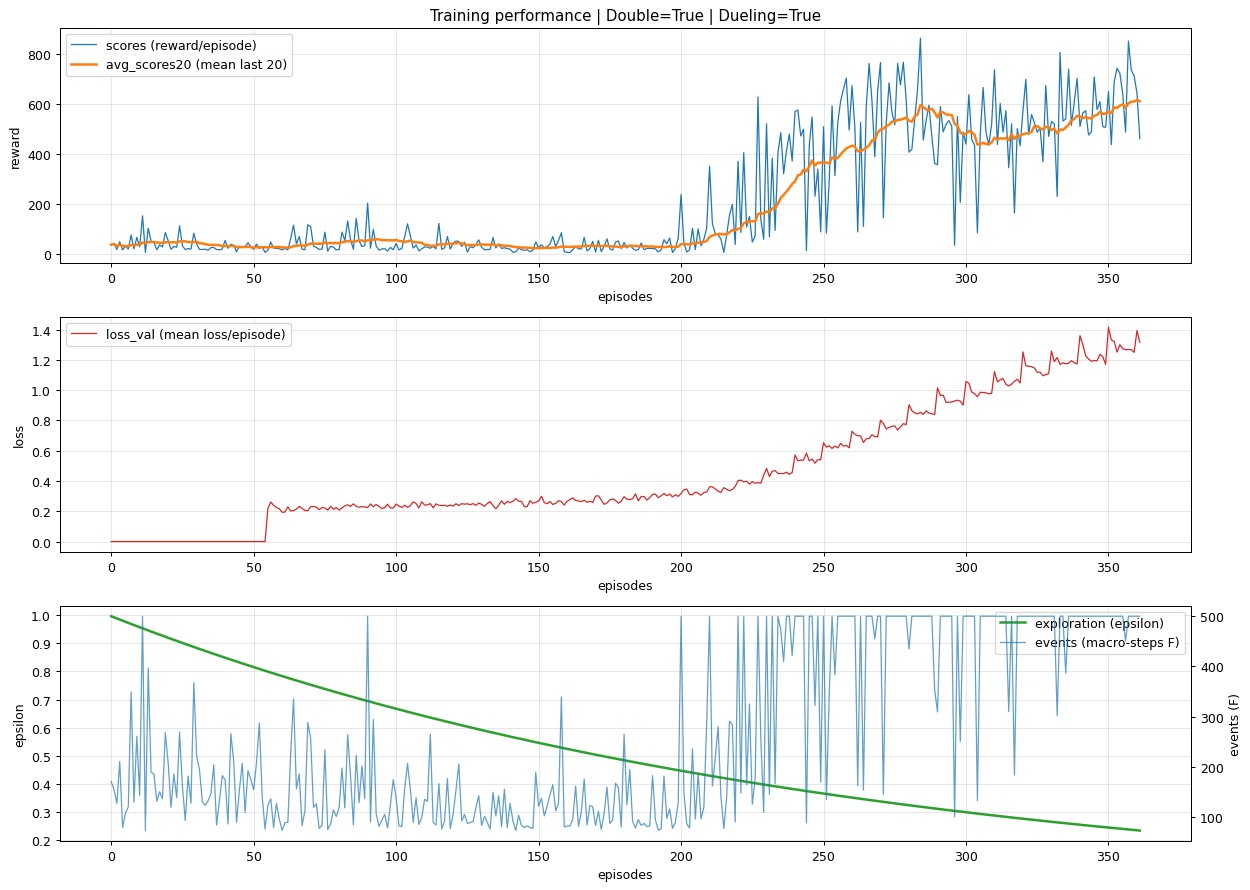

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10), dpi=90)

# 1) Reward / rendimiento
ax1 = plt.subplot(3, 1, 1)
ax1.plot(episodes, scores, label="scores (reward/episode)", linewidth=1)
ax1.plot(episodes, avg_scores20, label="avg_scores20 (mean last 20)", linewidth=2)
ax1.set_xlabel("episodes")
ax1.set_ylabel("reward")
ax1.set_title(f"Training performance | Double={usedoubleDQN} | Dueling={useDueling}")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="best")

# 2) Loss (estabilidad del aprendizaje)
ax2 = plt.subplot(3, 1, 2)
ax2.plot(episodes, loss_val, label="loss_val (mean loss/episode)", linewidth=1, color="tab:red")
ax2.set_xlabel("episodes")
ax2.set_ylabel("loss")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best")

# 3) Exploration + episode length (events)
ax3 = plt.subplot(3, 1, 3)
ax3.plot(episodes, exploration, label="exploration (epsilon)", linewidth=2, color="tab:green")
ax3.set_xlabel("episodes")
ax3.set_ylabel("epsilon")
ax3.grid(True, alpha=0.3)

ax3b = ax3.twinx()
ax3b.plot(episodes, events, label="events (macro-steps F)", linewidth=1, color="tab:blue", alpha=0.7)
ax3b.set_ylabel("events (F)")

# combinar leyendas de ax3 y ax3b
lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax3b.get_legend_handles_labels()
ax3.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()
plt.show()


# Cómo usarlo en el report (2 frases útiles)
    # scores/avg_scores20: muestran si el agente mejora y si cumple el criterio de rendimiento en una ventana reciente (últimos 20).
    # loss_val: ayuda a justificar si el entrenamiento es estable (no divergente) y cómo afectan los hiperparámetros (LR, gamma, batch, buffer).

Evaluation

In [ ]:
# evaluate() sirve para medir (de forma controlada y comparable) lo que tu agente ya sabe hacer, mientras que el DeepRL Loop sirve para aprender (explorar, recolectar experiencias y actualizar pesos). Son dos cosas distintas.

# evaluate() está pensada para:
  # Ejecutar un episodio sin aprendizaje (no llama a trainModel, no modifica pesos).
  # Ejecutar con política greedy (usa Network.policy(state), no epsilon-greedy), o sea: sin exploración aleatoria.
  # Poder hacerlo de forma reproducible usando seedTest (mismo track/condiciones según el entorno).
  # Devolver un número claro: reward total del episodio.

# En otras palabras: evaluate() es tu “modo examen”. El agente no practica, solo demuestra.

In [ ]:
def evaluate(Network,UseRandomizer,UseContinuous,seedTest):
    # Firma y creación de entorno --> Crea un entorno nuevo (mejor práctica que reutilizar env de entrenamiento)

    # OPCION A: SIN OBSTÁCULOS
    # env1 = gym.make("CarRacingObstacles-v3", render_mode="rgb_array",domain_randomize=UseRandomizer, continuous=UseContinuous)

    # OPCIÓN B: CON OBSTÁCULOS
    env1 = gym.make(
    "CarRacingObstacles-v3",
    render_mode="rgb_array",
    domain_randomize=UseRandomizer,
    continuous=UseContinuous,
    n_static_obstacles=5,
    n_dynamic_obstacles=5,
    n_mountains=5,
    use_ghost=True)

    envX = env1

    # Reset del entorno
    # new_state = envX.reset(options={"randomize": UseRandomizer},seed=seedTest)#,seed=6)
    new_state, _ = envX.reset(options={"randomize": UseRandomizer},seed=seedTest)#,seed=6)

    # Frame stacking inicial
    stackedStateX=[np.rollaxis(new_state, 2, 0).copy() for i in range(FrameStack)];
    state =torch.from_numpy(np.reshape(np.array(stackedStateX),(FrameSize*FrameStack,96,96)) ).float().to(device)

    # Variables de loop
    i=0
    Network.eval()
    resetStatus=0;

    # Loop de evaluación del episodio
    totalreward=0
    while True:
        action = Network.policy(state);
        reward=0
        for x in range(ControlSteps):
            new_state, r, done, truncated, _  = envX.step(action_space[action.item()])
            reward+=r
            # if(done):
            if done or truncated:
                break

        # Acumular reward y actualizar stack
        totalreward+=reward;
        stackedStateX.pop(0)

        stackedStateX.append(np.rollaxis(new_state, 2, 0).copy())
        state=torch.from_numpy(np.reshape(np.array(stackedStateX),(FrameSize*FrameStack,96,96))).float().to(device)
        i=i+1;
        if done or truncated:
          break;

    # Cerrar y devolver reward total
    envX.close()
    return totalreward;

In [ ]:
import numpy as np

rewards_no_rand = []
rewards_rand = []

DISASTER_THRESHOLD = 200  # o 0

print("=== Evaluation: UseRandomize=False ===")
for s in [1,2,3,4,5]:
    r = evaluate(policy_net, False, UseContinuousControl, s)
    rewards_no_rand.append(r)
    print(f"Seed {s:2d} | Total Reward: {r:.3f}")

print("\n=== Evaluation: UseRandomize=True ===")
for s in [6,7,8,9,10]:
    r = evaluate(policy_net, True, UseContinuousControl, s)
    rewards_rand.append(r)
    print(f"Seed {s:2d} | Total Reward: {r:.3f}")

def summarize(name, rs):
    mean_r = float(np.mean(rs))
    std_r  = float(np.std(rs))
    min_r  = float(np.min(rs))
    n_dis  = sum(r < DISASTER_THRESHOLD for r in rs)
    print(f"\n--- {name} ---")
    print(f"Mean: {mean_r:.3f} | Std: {std_r:.3f} | Min: {min_r:.3f}")
    print(f"Disasters (reward < {DISASTER_THRESHOLD}): {n_dis}/{len(rs)}")

summarize("No randomize (seeds 1-5)", rewards_no_rand)
summarize("Randomize (seeds 6-10)", rewards_rand)

all_rewards = rewards_no_rand + rewards_rand
summarize("ALL (seeds 1-10)", all_rewards)


=== Evaluation: UseRandomize=False ===
[CarRacingObstacles] Placed mountain around tile 0
[CarRacingObstacles] Placed mountain around tile 54
[CarRacingObstacles] Placed mountain around tile 109
[CarRacingObstacles] Placed mountain around tile 164
[CarRacingObstacles] Placed mountain around tile 219
Seed  1 | Total Reward: 485.698
[CarRacingObstacles] Placed mountain around tile 0
[CarRacingObstacles] Placed mountain around tile 66
[CarRacingObstacles] Placed mountain around tile 133
[CarRacingObstacles] Placed mountain around tile 200
[CarRacingObstacles] Placed mountain around tile 267
Seed  2 | Total Reward: 862.084
[CarRacingObstacles] Placed mountain around tile 0
[CarRacingObstacles] Placed mountain around tile 54
[CarRacingObstacles] Placed mountain around tile 108
[CarRacingObstacles] Placed mountain around tile 162
[CarRacingObstacles] Placed mountain around tile 216
Seed  3 | Total Reward: 472.636
[CarRacingObstacles] Placed mountain around tile 0
[CarRacingObstacles] Placed 

In [ ]:
# Este bloque ejecuta la función evaluate(...) 10 veces para medir la recompensa total (Total Reward) del modelo entrenado (policy_net) bajo condiciones reproducibles (controladas por seed), y lo imprime.
# La idea es tener una evaluación rápida tipo:
  # 5 episodios con UseRandomizer=False (seeds 1–5)
  # 5 episodios con UseRandomizer=True (seeds 6–10)
# --> Esto se alinea bastante bien con lo que pide el enunciado: reportar rendimiento en varios escenarios (incluyendo con randomización).

# Assignment 3 Part 2
For the second part, select one of the available observation modes (e.g., DIRECTION AND ERROR or LOCAL). During the practical classes, you can also request access to other observation modes based on the available scenarios. You should train both the DQN and Double Dueling DQN in the static scenarios. The evaluation code includes a split between training and testing scenarios, but you should also include the comparison when dynamic objects are present (dynamic objs=True). Tutorial code is available in the environment’s GitHub repository4).


In [ ]:
!git clone https://github.com/luisgarrote/IndoorRobotEnv.git
%cd IndoorRobotEnv
!pip -q install -r requirements.txt
!pip -q install -e .


Cloning into 'IndoorRobotEnv'...
remote: Enumerating objects: 75, done.
remote: Counting objects: 100% (75/75), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 75 (delta 39), reused 1 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (75/75), 127.22 KiB | 6.06 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/IndoorRobotEnv/IndoorRobotEnv/IndoorRobotEnv/IndoorRobotEnv
  Preparing metadata (setup.py) ... done


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from matplotlib.pyplot import figure

import gymnasium as gym
import torch
from torch.utils import data
import torch.nn as nn
import torch.optim as optim
import torch.autograd as autograd
import torch.nn.functional as F
import random
from gymnasium import wrappers
import copy
from gymnasium.wrappers import RecordVideo

import glob
import io
import base64
from IPython.display import HTML
from IPython import display as ipythondisplay

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

from indoor_robot_2025_animated import IndoorRobot2025Env,ObservationMode
gym.register(
    id="IndoorRobot2025-v0",
    entry_point="indoor_robot_2025_animated:IndoorRobot2025Env",
)

/usr/local/lib/python3.12/dist-packages/gymnasium/envs/registration.py:636: UserWarning: WARN: Overriding environment IndoorRobot2025-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")


In [ ]:
print(list(ObservationMode))


[<ObservationMode.POSE: 1>, <ObservationMode.DIRECTION: 2>, <ObservationMode.POSE_AND_ERROR: 3>, <ObservationMode.DIRECTION_AND_ERROR: 4>, <ObservationMode.LOCAL: 5>]


In [ ]:
ENV_ID = "IndoorRobot2025-v0"
OBS_MODE = ObservationMode.DIRECTION_AND_ERROR
print("device =", device)
print("ENV_ID =", ENV_ID)
print("OBS_MODE =", OBS_MODE)

device = cpu
ENV_ID = IndoorRobot2025-v0
OBS_MODE = ObservationMode.DIRECTION_AND_ERROR


In [ ]:
env = gym.make(ENV_ID, observation_mode=OBS_MODE)

obs, info = env.reset()
state = np.asarray(obs, dtype=np.float32)
state_dim = state.shape[0]
n_actions = env.action_space.n

print("action_space =", env.action_space)
print("obs example =", state)
print("state_dim =", state_dim, "n_actions =", n_actions)

action_space = Discrete(10)
obs example = [0.57179266 0.8203982  0.962107   0.        ]
state_dim = 4 n_actions = 10


/usr/local/lib/python3.12/dist-packages/gymnasium/utils/passive_env_checker.py:158: UserWarning: WARN: The obs returned by the `reset()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


In [ ]:

GAMMA = 0.99
LR = 1e-4
BATCH_SIZE = 128
REPLAY_CAPACITY = 50_000
WARMUP_STEPS = 2_000
TARGET_UPDATE_FREQ = 1_000
TOTAL_STEPS = 50_000

EPS_START = 1.0
EPS_END = 0.05
EPS_DECAY_STEPS = 50_000


In [ ]:
class ReplayBuffer:
    def __init__(self, capacity=50000):
        self.buf = deque(maxlen=capacity)

    def push(self, s, a, r, s2, done):
        self.buf.append((s, a, r, s2, done))

    def sample(self, batch_size):
        batch = random.sample(self.buf, batch_size)
        s, a, r, s2, done = map(np.array, zip(*batch))
        return (s.astype(np.float32),
                a.astype(np.int64),
                r.astype(np.float32),
                s2.astype(np.float32),
                done.astype(np.float32))

    def __len__(self):
        return len(self.buf)

replay = ReplayBuffer(REPLAY_CAPACITY)

In [ ]:
# @title
class QNet(nn.Module):
    def __init__(self, state_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, n_actions)
        )

    def forward(self, x):
        return self.net(x)

q_net = QNet(state_dim, n_actions).to(device)
target_net = QNet(state_dim, n_actions).to(device)
target_net.load_state_dict(q_net.state_dict())
target_net.eval()

optimizer = optim.Adam(q_net.parameters(), lr=LR)

print(q_net)

QNet(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


/usr/local/lib/python3.12/dist-packages/gymnasium/utils/passive_env_checker.py:158: UserWarning: WARN: The obs returned by the `step()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


episode=10, avg_reward(last10)=-11.18, step=144, eps=0.997
episode=20, avg_reward(last10)=-10.74, step=301, eps=0.994
episode=30, avg_reward(last10)=-10.02, step=427, eps=0.992
episode=40, avg_reward(last10)=-10.01, step=555, eps=0.989
episode=50, avg_reward(last10)=-9.64, step=681, eps=0.987
episode=60, avg_reward(last10)=-10.57, step=832, eps=0.984
episode=70, avg_reward(last10)=-10.07, step=982, eps=0.981
episode=80, avg_reward(last10)=-10.72, step=1134, eps=0.978
episode=90, avg_reward(last10)=-9.74, step=1297, eps=0.975
episode=100, avg_reward(last10)=-9.98, step=1432, eps=0.973
episode=110, avg_reward(last10)=-11.06, step=1647, eps=0.969
episode=120, avg_reward(last10)=-9.80, step=1790, eps=0.966
episode=130, avg_reward(last10)=-10.41, step=1988, eps=0.962
episode=140, avg_reward(last10)=-11.06, step=2168, eps=0.959
episode=150, avg_reward(last10)=-9.79, step=2333, eps=0.956
episode=160, avg_reward(last10)=-10.08, step=2531, eps=0.952
episode=170, avg_reward(last10)=-10.35, step=

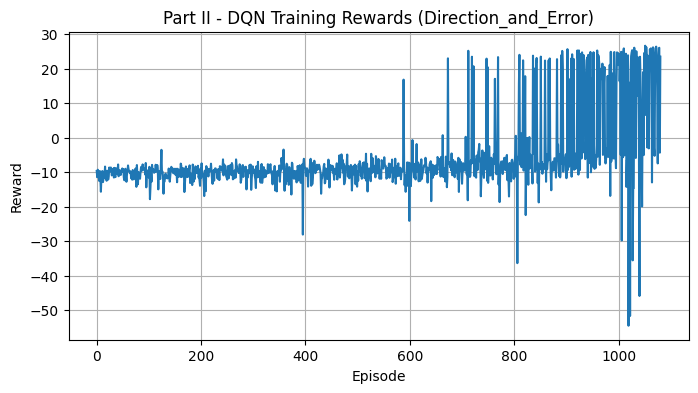

In [ ]:
def epsilon_by_step(step):
    t = min(step, EPS_DECAY_STEPS)
    return EPS_START + (EPS_END - EPS_START) * (t / EPS_DECAY_STEPS)

@torch.no_grad()
def select_action(state_np, step):
    eps = epsilon_by_step(step)

    if random.random() < eps:
        return random.randrange(n_actions)

    s = torch.tensor(state_np, dtype=torch.float32, device=device).unsqueeze(0)  # [1,4]
    q = q_net(s)  # [1,10]
    return int(torch.argmax(q, dim=1).item())


# train

episode_rewards = []
episode_reward = 0.0
step = 0

obs, info = env.reset()
state = np.asarray(obs, dtype=np.float32)

while step < TOTAL_STEPS:

    # select action
    action = select_action(state, step)

    #
    next_obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    next_state = np.asarray(next_obs, dtype=np.float32)

    replay.push(state, action, reward, next_state, done)

    episode_reward += reward

    if len(replay) >= BATCH_SIZE and step >= WARMUP_STEPS:

        s, a, r, s2, d = replay.sample(BATCH_SIZE)

        s  = torch.tensor(s, device=device)
        a  = torch.tensor(a, device=device)
        r  = torch.tensor(r, device=device)
        s2 = torch.tensor(s2, device=device)
        d  = torch.tensor(d, device=device)

        q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

        # DQN target: y = r + gamma*(1-done)*max_a' Q_target(s', a')
        with torch.no_grad():
            q_next = target_net(s2).max(dim=1).values
            y = r + GAMMA * (1.0 - d) * q_next

        # loss
        loss = F.smooth_l1_loss(q_sa, y)

        # q_net
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    #  target
    if step % TARGET_UPDATE_FREQ == 0:
        target_net.load_state_dict(q_net.state_dict())

    state = next_state
    step += 1

    if done:
        episode_rewards.append(episode_reward)

        if len(episode_rewards) % 10 == 0:
            print(f"episode={len(episode_rewards)}, avg_reward(last10)={np.mean(episode_rewards[-10:]):.2f}, step={step}, eps={epsilon_by_step(step):.3f}")

        episode_reward = 0.0
        obs, info = env.reset()
        state = np.asarray(obs, dtype=np.float32)

env.close()
print("Training finished. Total episodes:", len(episode_rewards))

plt.figure(figsize=(8,4))
plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Part II - DQN Training Rewards (Direction_and_Error)")
plt.grid(True)
plt.show()

In [ ]:
torch.save(q_net.state_dict(), "part2_dqn_qnet.pt")
torch.save(target_net.state_dict(), "part2_dqn_targetnet.pt")
np.save("part2_dqn_episode_rewards.npy", np.array(episode_rewards, dtype=np.float32))

print("Saved DQN: part2_dqn_qnet.pt and part2_dqn_episode_rewards.npy")

Saved DQN: part2_dqn_qnet.pt and part2_dqn_episode_rewards.npy


In [ ]:
# Double DQN: initial net
q_net = QNet(state_dim, n_actions).to(device)
target_net = QNet(state_dim, n_actions).to(device)
target_net.load_state_dict(q_net.state_dict())
target_net.eval()

optimizer = optim.Adam(q_net.parameters(), lr=LR)

replay = ReplayBuffer(REPLAY_CAPACITY)
episode_rewards = []
episode_reward = 0.0
step = 0

obs, info = env.reset()
state = np.asarray(obs, dtype=np.float32)

print("Double DQN init done")


Double DQN init done


In [ ]:
#  Double DQN Training
while step < TOTAL_STEPS:

    action = select_action(state, step)

    next_obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    next_state = np.asarray(next_obs, dtype=np.float32)

    replay.push(state, action, reward, next_state, done)
    episode_reward += reward

    if len(replay) >= BATCH_SIZE and step >= WARMUP_STEPS:
        s, a, r, s2, d = replay.sample(BATCH_SIZE)

        s  = torch.tensor(s, device=device)
        a  = torch.tensor(a, device=device)
        r  = torch.tensor(r, device=device)
        s2 = torch.tensor(s2, device=device)
        d  = torch.tensor(d, device=device)

        q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

        # only change here
        with torch.no_grad():

            a_star = q_net(s2).argmax(dim=1)
            q_next = target_net(s2).gather(1, a_star.unsqueeze(1)).squeeze(1)
            y = r + GAMMA * (1.0 - d) * q_next

        loss = F.smooth_l1_loss(q_sa, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if step % TARGET_UPDATE_FREQ == 0:
        target_net.load_state_dict(q_net.state_dict())

    state = next_state
    step += 1

    if done:
        episode_rewards.append(episode_reward)
        if len(episode_rewards) % 10 == 0:
            print(f"[DoubleDQN] episode={len(episode_rewards)}, avg_reward(last10)={np.mean(episode_rewards[-10:]):.2f}, step={step}, eps={epsilon_by_step(step):.3f}")
        episode_reward = 0.0
        obs, info = env.reset()
        state = np.asarray(obs, dtype=np.float32)

print("Double DQN training finished. episodes:", len(episode_rewards))


[DoubleDQN] episode=10, avg_reward(last10)=-9.99, step=144, eps=0.997
[DoubleDQN] episode=20, avg_reward(last10)=-10.54, step=283, eps=0.995
[DoubleDQN] episode=30, avg_reward(last10)=-9.85, step=388, eps=0.993
[DoubleDQN] episode=40, avg_reward(last10)=-10.09, step=508, eps=0.990
[DoubleDQN] episode=50, avg_reward(last10)=-10.15, step=685, eps=0.987
[DoubleDQN] episode=60, avg_reward(last10)=-10.76, step=842, eps=0.984
[DoubleDQN] episode=70, avg_reward(last10)=-10.40, step=1063, eps=0.980
[DoubleDQN] episode=80, avg_reward(last10)=-9.91, step=1182, eps=0.978
[DoubleDQN] episode=90, avg_reward(last10)=-11.23, step=1368, eps=0.974
[DoubleDQN] episode=100, avg_reward(last10)=-10.76, step=1596, eps=0.970
[DoubleDQN] episode=110, avg_reward(last10)=-10.58, step=1734, eps=0.967
[DoubleDQN] episode=120, avg_reward(last10)=-11.11, step=1918, eps=0.964
[DoubleDQN] episode=130, avg_reward(last10)=-10.26, step=2044, eps=0.961
[DoubleDQN] episode=140, avg_reward(last10)=-9.58, step=2170, eps=0.9

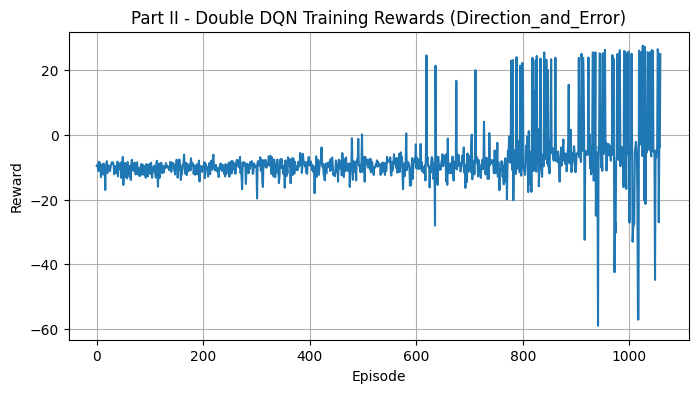

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Part II - Double DQN Training Rewards (Direction_and_Error)")
plt.grid(True)
plt.show()

In [ ]:
# save double DQN
torch.save(q_net.state_dict(), "part2_double_qnet.pt")
torch.save(target_net.state_dict(), "part2_double_targetnet.pt")
np.save("part2_double_episode_rewards.npy", np.array(episode_rewards, dtype=np.float32))

print("Saved Double DQN: part2_double_qnet.pt and part2_double_episode_rewards.npy")


Saved Double DQN: part2_double_qnet.pt and part2_double_episode_rewards.npy


In [ ]:
# Double Dueling DQN
class DuelingQNet(nn.Module):
    def __init__(self, state_dim, n_actions):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU()
        )
        self.V = nn.Linear(128, 1)
        self.A = nn.Linear(128, n_actions)

    def forward(self, x):
        h = self.backbone(x)
        v = self.V(h)                     # [B,1]
        a = self.A(h)                     # [B,n_actions]
        q = v + (a - a.mean(dim=1, keepdim=True))
        return q


In [ ]:
# Double Dueling DQN: initial
q_net = DuelingQNet(state_dim, n_actions).to(device)
target_net = DuelingQNet(state_dim, n_actions).to(device)
target_net.load_state_dict(q_net.state_dict())
target_net.eval()

optimizer = optim.Adam(q_net.parameters(), lr=LR)

replay = ReplayBuffer(REPLAY_CAPACITY)
episode_rewards = []
episode_reward = 0.0
step = 0

obs, info = env.reset()
state = np.asarray(obs, dtype=np.float32)

print("Double Dueling init done")


Double Dueling init done


In [ ]:
# Double Dueling DQN Training
while step < TOTAL_STEPS:

    action = select_action(state, step)

    next_obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    next_state = np.asarray(next_obs, dtype=np.float32)

    replay.push(state, action, reward, next_state, done)
    episode_reward += reward

    if len(replay) >= BATCH_SIZE and step >= WARMUP_STEPS:
        s, a, r, s2, d = replay.sample(BATCH_SIZE)

        s  = torch.tensor(s, device=device)
        a  = torch.tensor(a, device=device)
        r  = torch.tensor(r, device=device)
        s2 = torch.tensor(s2, device=device)
        d  = torch.tensor(d, device=device)

        q_sa = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

        # Double target（
        with torch.no_grad():
            a_star = q_net(s2).argmax(dim=1)
            q_next = target_net(s2).gather(1, a_star.unsqueeze(1)).squeeze(1)
            y = r + GAMMA * (1.0 - d) * q_next

        loss = F.smooth_l1_loss(q_sa, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if step % TARGET_UPDATE_FREQ == 0:
        target_net.load_state_dict(q_net.state_dict())

    state = next_state
    step += 1

    if done:
        episode_rewards.append(episode_reward)
        if len(episode_rewards) % 10 == 0:
            print(f"[DoubleDueling] episode={len(episode_rewards)}, avg_reward(last10)={np.mean(episode_rewards[-10:]):.2f}, step={step}, eps={epsilon_by_step(step):.3f}")
        episode_reward = 0.0
        obs, info = env.reset()
        state = np.asarray(obs, dtype=np.float32)

print("Double Dueling training finished. episodes:", len(episode_rewards))


[DoubleDueling] episode=10, avg_reward(last10)=-10.07, step=169, eps=0.997
[DoubleDueling] episode=20, avg_reward(last10)=-9.72, step=357, eps=0.993
[DoubleDueling] episode=30, avg_reward(last10)=-10.55, step=479, eps=0.991
[DoubleDueling] episode=40, avg_reward(last10)=-9.86, step=634, eps=0.988
[DoubleDueling] episode=50, avg_reward(last10)=-9.47, step=755, eps=0.986
[DoubleDueling] episode=60, avg_reward(last10)=-10.04, step=924, eps=0.982
[DoubleDueling] episode=70, avg_reward(last10)=-9.75, step=1128, eps=0.979
[DoubleDueling] episode=80, avg_reward(last10)=-9.56, step=1256, eps=0.976
[DoubleDueling] episode=90, avg_reward(last10)=-11.37, step=1459, eps=0.972
[DoubleDueling] episode=100, avg_reward(last10)=-10.25, step=1587, eps=0.970
[DoubleDueling] episode=110, avg_reward(last10)=-9.67, step=1761, eps=0.967
[DoubleDueling] episode=120, avg_reward(last10)=-11.35, step=1960, eps=0.963
[DoubleDueling] episode=130, avg_reward(last10)=-9.78, step=2086, eps=0.960
[DoubleDueling] episo

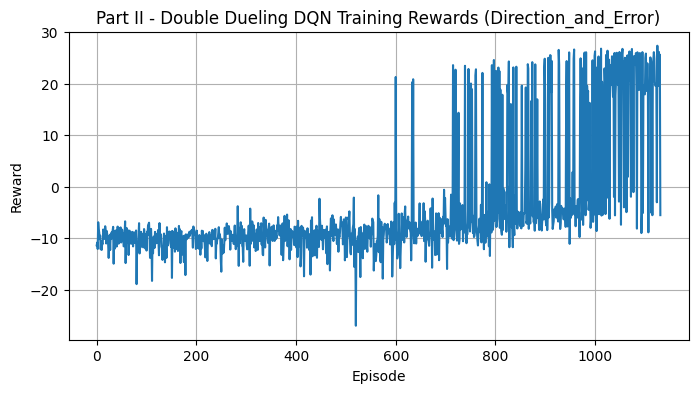

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(episode_rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Part II - Double Dueling DQN Training Rewards (Direction_and_Error)")
plt.grid(True)
plt.show()

In [ ]:
torch.save(q_net.state_dict(), "part2_double_dueling_qnet.pt")
torch.save(target_net.state_dict(), "part2_double_dueling_targetnet.pt")
np.save("part2_double_dueling_episode_rewards.npy", np.array(episode_rewards, dtype=np.float32))

print("Saved Double Dueling DQN: part2_double_dueling_qnet.pt and part2_double_dueling_episode_rewards.npy")


Saved Double Dueling DQN: part2_double_dueling_qnet.pt and part2_double_dueling_episode_rewards.npy


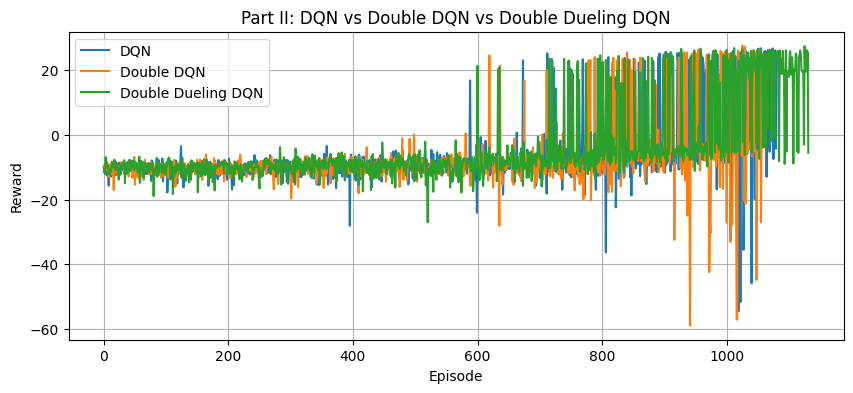

In [ ]:
import matplotlib.pyplot as plt

dqn_rewards = np.load("part2_dqn_episode_rewards.npy")
double_rewards = np.load("part2_double_episode_rewards.npy")
double_dueling_rewards = np.load("part2_double_dueling_episode_rewards.npy")

plt.figure(figsize=(10,4))
plt.plot(dqn_rewards, label="DQN")
plt.plot(double_rewards, label="Double DQN")
plt.plot(double_dueling_rewards, label="Double Dueling DQN")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Part II: DQN vs Double DQN vs Double Dueling DQN")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
EVAL_EPISODES = 50

class QNet(nn.Module):
    def __init__(self, state_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, n_actions)
        )

    def forward(self, x):
        return self.net(x)

class DuelingQNet(nn.Module):
    def __init__(self, state_dim, n_actions):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU()
        )
        self.V = nn.Linear(128, 1)
        self.A = nn.Linear(128, n_actions)

    def forward(self, x):
        h = self.backbone(x)
        v = self.V(h)                     # [B,1]
        a = self.A(h)                     # [B,n_actions]
        q = v + (a - a.mean(dim=1, keepdim=True))
        return q

In [ ]:
env_tmp = gym.make(
    "IndoorRobot2025-v0",
    observation_mode=OBS_MODE,
    scenario_split="train",
    dynamic_objs=False
)
obs, info = env_tmp.reset()
state_dim = int(np.asarray(obs, dtype=np.float32).shape[0])
n_actions = int(env_tmp.action_space.n)
env_tmp.close()

print("state_dim =", state_dim, "| n_actions =", n_actions)

state_dim = 4 | n_actions = 10


In [ ]:
def load_model(net_type, path):
    """
    net_type: "dqn" -> QNet
              "dueling" -> DuelingQNet
    """
    if net_type == "dqn":
        net = QNet(state_dim, n_actions).to(device)
    elif net_type == "dueling":
        net = DuelingQNet(state_dim, n_actions).to(device)
    else:
        raise ValueError("Unknown net_type")

    net.load_state_dict(torch.load(path, map_location=device))
    net.eval()
    return net

models = {
    "DQN": load_model("dqn", "part2_dqn_qnet.pt"),
    "DoubleDQN": load_model("dqn", "part2_double_qnet.pt"),
    "DoubleDueling": load_model("dueling", "part2_double_dueling_qnet.pt"),
}

print("Models loaded:", list(models.keys()))

Models loaded: ['DQN', 'DoubleDQN', 'DoubleDueling']


In [ ]:
@torch.no_grad()
def greedy_action(net, state_np):
    s = torch.tensor(state_np, dtype=torch.float32, device=device).unsqueeze(0)  # [1,dim]
    q = net(s)  # [1,n_actions]
    return int(torch.argmax(q, dim=1).item())

def evaluate_model_on_setting(net, scenario_split, dynamic_flag, episodes=50):
    """
    scenario_split: "train" or "test"
    dynamic_flag: True/False (dynamic_objs)
    """
    env = gym.make(
        "IndoorRobot2025-v0",
        observation_mode=OBS_MODE,
        scenario_split=scenario_split,
        dynamic_objs=dynamic_flag
    )

    rewards = []
    lengths = []
    success_flags = []

    for _ in range(episodes):
        obs, info = env.reset()
        state = np.asarray(obs, dtype=np.float32)

        done = False
        ep_r = 0.0
        ep_len = 0
        success = None

        while not done:
            a = greedy_action(net, state)
            next_obs, r, terminated, truncated, info = env.step(a)
            done = bool(terminated or truncated)

            state = np.asarray(next_obs, dtype=np.float32)
            ep_r += float(r)
            ep_len += 1

            if isinstance(info, dict):
                if "success" in info:
                    success = bool(info["success"])
                elif "is_success" in info:
                    success = bool(info["is_success"])


        rewards.append(ep_r)
        lengths.append(ep_len)
        success_flags.append(success)

    env.close()

    mean_r = float(np.mean(rewards))
    std_r = float(np.std(rewards))
    mean_len = float(np.mean(lengths))

    if all(x is None for x in success_flags):
        success_rate = None
    else:
        valid = [1.0 if x else 0.0 for x in success_flags if x is not None]
        success_rate = float(np.mean(valid)) if len(valid) > 0 else None

    return {
        "mean_reward": mean_r,
        "std_reward": std_r,
        "mean_length": mean_len,
        "success_rate": success_rate
    }

In [ ]:
settings = [
    ("train", False),
    ("test",  False),
    ("train", True),
    ("test",  True),
]

results = []  # list of dict rows

for model_name, net in models.items():
    for split, dyn in settings:
        print(f"Evaluating {model_name:>13s} | split={split:>5s} | dynamic={dyn} ...")
        res = evaluate_model_on_setting(net, split, dyn, episodes=EVAL_EPISODES)
        row = {
            "Model": model_name,
            "Split": split,
            "Dynamic": dyn,
            "MeanReward": res["mean_reward"],
            "StdReward": res["std_reward"],
            "MeanLength": res["mean_length"],
            "SuccessRate": res["success_rate"],
        }
        results.append(row)

Evaluating           DQN | split=train | dynamic=False ...
Evaluating           DQN | split= test | dynamic=False ...
Evaluating           DQN | split=train | dynamic=True ...
Evaluating           DQN | split= test | dynamic=True ...
Evaluating     DoubleDQN | split=train | dynamic=False ...
Evaluating     DoubleDQN | split= test | dynamic=False ...
Evaluating     DoubleDQN | split=train | dynamic=True ...
Evaluating     DoubleDQN | split= test | dynamic=True ...
Evaluating DoubleDueling | split=train | dynamic=False ...
Evaluating DoubleDueling | split= test | dynamic=False ...
Evaluating DoubleDueling | split=train | dynamic=True ...
Evaluating DoubleDueling | split= test | dynamic=True ...


In [ ]:
try:
    import pandas as pd
    df = pd.DataFrame(results)
    print("\nFinal Table:")
    display(df)
except Exception:
    pass


Final Table:


,Model,Split,Dynamic,MeanReward,StdReward,MeanLength,SuccessRate
0,DQN,train,False,-2.526709,29.052217,388.40,None
1,DQN,test,False,17.138081,17.747901,96.88,None
2,DQN,train,True,-3.280604,28.051261,331.42,None
3,DQN,test,True,7.198174,26.153857,113.58,None
4,DoubleDQN,train,False,-1.725097,26.210433,255.50,None
5,DoubleDQN,test,False,-7.197725,34.940402,512.44,None
6,DoubleDQN,train,True,-5.607086,24.141920,258.52,None
7,DoubleDQN,test,True,-12.801750,29.842692,476.94,None
8,DoubleDueling,train,False,20.935151,6.436912,93.02,None
9,DoubleDueling,test,False,23.377219,6.524525,87.52,None


In [ ]:
obs, info = env.reset()
print("info keys:", info.keys())
print(info)


info keys: dict_keys(['goal', 'robot', 'scenario_id', 'path_world', 'last_action', 'total_reward'])
{'goal': {'x': 6.5, 'y': 6.0}, 'robot': {'x': -0.25, 'y': -6.25, 'theta': 1.0671700239181519}, 'scenario_id': 2, 'path_world': [(-0.25, -6.25), (-0.039121681402352906, -6.2390121192744425), (0.14222761698283892, -6.214159910412658), (0.2726334060186223, -6.157898112347487), (0.3480887141296187, -6.052447553112623), (0.382869223085358, -5.89167325249753), (0.3957937344309997, -5.686812239124051), (0.3997364891908952, -5.455798199923524), (0.4007388324313935, -5.212581227159297), (0.4009525704983804, -4.964683164110082), (0.4009904418924922, -4.715258541148812), (0.40099575853869684, -4.465399822051111), (0.40099624082409324, -4.215431339671679), (0.40099622470700536, -3.96543779581662), (0.40099620425162313, -3.7154390200176914), (0.40099619877975545, -3.465439225958615), (0.4009962033646758, -3.2154391593340312), (0.4009962516304793, -2.9654383246536), (0.4009966009021997, -2.71543228183